In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import machine_learning_models as mlm
pd.set_option('display.max_rows', 100)

In [2]:
df = pd.read_csv(r'C:\Users\mechz\Documents\Jobs_Analysis\job_postings.csv')
X = df.drop(columns=['salary_year_avg'])
predictors = X.columns.to_list()
numerical_columns = ['job_posted_year', 'job_posted_month_sine']
numerical_indices = X.columns.get_indexer(numerical_columns)
X = X.to_numpy()
y = df['salary_year_avg'].to_numpy()

training_index, testing_index = mlm.train_test_split(X.shape[0], 10000)
X_training = X[training_index]
y_training = y[training_index]
X_testing = X[testing_index]
y_testing = y[testing_index]

for index in numerical_indices:
    mean = np.mean(X_training[:,index])
    std = np.std(X_training[:, index])
    X_training[:,index] = (X_training[:,index] - mean) / std
    X_testing[:,index] = (X_testing[:,index] - mean) / std

print(f'The mean, median, and standard deviation of the salary are {np.mean(y):.3f}, {np.median(y):.3f}, and {np.std(y):.3f} respectively.')

The mean, median, and standard deviation of the salary are 122390.906, 115000.000, and 47019.486 respectively.


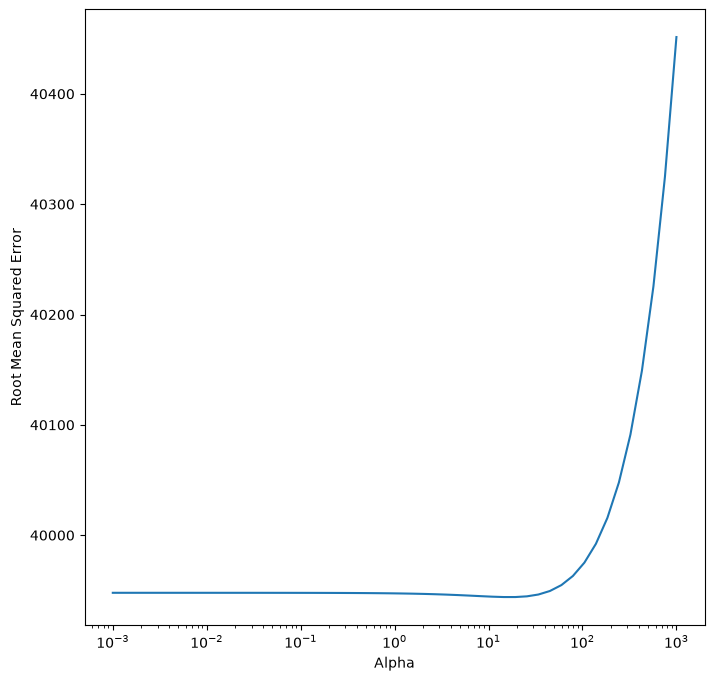

The best alpha value is 14.563 which gives a testing root mean squared error of 38611.384 and testing R squared score of 0.295.


,value
variable,
job_title_short_Senior Data Scientist,21392.996021
job_country_South Africa,14993.387277
job_country_United States,13777.577715
job_title_short_Senior Data Engineer,13356.285796
job_country_Sudan,11037.739569
job_via_LinkedIn,10830.828341
job_via_Built In,10345.071280
job_title_short_Software Engineer,8848.064780
job_title_short_Machine Learning Engineer,8579.888734


In [3]:
alphas = np.logspace(-3, 3, 50)
rmses = {}
for alpha in alphas:
    rmses_one_fold = []
    for fold in mlm.kfold_cross_validation(5, X_training.shape[0]):
        inner_model = mlm.Ridge_Regression()
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0), alpha=alpha)
        predictions = inner_model.predict(X_training[fold])
        rmse = np.sqrt(np.mean((y_training[fold] - predictions)**2))
        rmses_one_fold.append(rmse)
    average_rmse = np.mean(rmses_one_fold)
    rmses.update({alpha:average_rmse})
best_alpha = min(rmses, key=rmses.get)

fig, ax = plt.subplots(figsize=(8,8))
ax.semilogx(rmses.keys(), rmses.values())
ax.set_xlabel('Alpha')
ax.set_ylabel('Root Mean Squared Error')
plt.show()

final_model = mlm.Ridge_Regression()
final_model.fit(X_training, y_training, alpha=best_alpha)
predictions = final_model.predict(X_testing)
rmse = np.sqrt(np.mean((y_testing - predictions)**2))
r2 = 1 - (np.sum((y_testing - predictions)**2)) / (np.sum((y_testing - np.mean(y_testing))**2))

print(f'The best alpha value is {best_alpha:.3f} which gives a testing root mean squared error of {rmse:.3f} and testing R squared score of {r2:.3f}.')
full_model = mlm.Ridge_Regression()
full_model.fit(X, y, alpha=best_alpha)
parameters = predictors
parameters_dictionary = dict(zip(parameters, full_model.parameters))
parameters_df = pd.DataFrame(parameters_dictionary)
parameters_df = pd.melt(parameters_df).set_index('variable', drop=True).sort_values(by='value', ascending=False)
display(parameters_df)

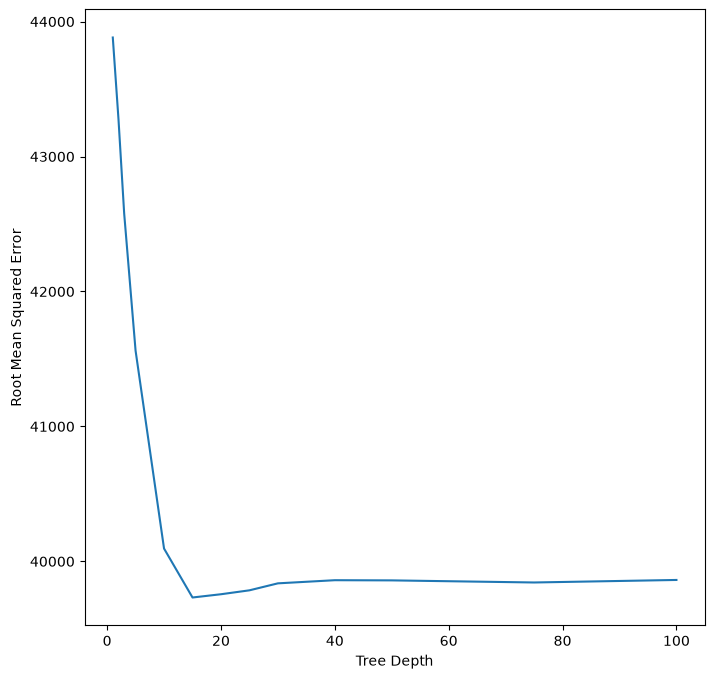

The best tree depth is 15 which gives a testing root mean squared error of 38113.917 and testing R squared score of 0.313.


,permutation_importance,sse_importance,direction
variables,,,
job_title_short_Data Analyst,26.95,35.99,-40213.799499
job_health_insurance,11.82,5.47,12417.419299
job_via_LinkedIn,4.10,2.97,9748.779190
job_via_other,3.77,2.06,4573.674748
job_country_other,3.69,2.87,-4837.109364
job_via_Ladders,3.64,2.22,4300.884781
job_title_short_Business Analyst,3.38,5.58,-28933.986940
skills_python,3.30,1.78,5098.144239
job_title_short_Data Engineer,3.29,1.87,-4853.232920


In [4]:
depths = [1, 2, 3, 5, 10, 15, 20, 25, 30, 40, 50, 75, 100]
rmses = []
for depth in depths:
    rmses_one_fold = []
    for fold in mlm.kfold_cross_validation(5, len(y_training)):
        inner_model = mlm.Regression_Tree(X.shape[1], max_depth=depth)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold))
        predictions = inner_model.predict(X_training[fold])
        rmse = np.sqrt(np.mean((y_training[fold] - predictions)**2))
        rmses_one_fold.append(rmse)
    rmses.append(np.mean(rmses_one_fold))
lowest_rmse = min(rmses)
best_depth = depths[rmses.index(lowest_rmse)]

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(depths, rmses)
ax.set_xlabel('Tree Depth')
ax.set_ylabel('Root Mean Squared Error')
plt.show()

full_model = mlm.Regression_Tree(X.shape[1], max_depth=best_depth)
full_model.fit(X_training, y_training)
predictions = inner_model.predict(X_testing)
rmse = np.sqrt(np.mean((y_testing - predictions)**2))
r2 = 1 - (np.sum((y_testing - predictions)**2)) / (np.sum((y_testing - np.mean(y_testing))**2))
print(f'The best tree depth is {best_depth} which gives a testing root mean squared error of {rmse:.3f} and testing R squared score of {r2:.3f}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'permutation_importance':np.round(full_model.permutation_importances(X_testing, y_testing) * 100, 2), 'sse_importance':np.round(full_model.feature_importances() * 100, 2), 'direction':full_model.direction_of_change()}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by='permutation_importance', ascending=False).set_index('variables', drop=True)
display(parameters_df)

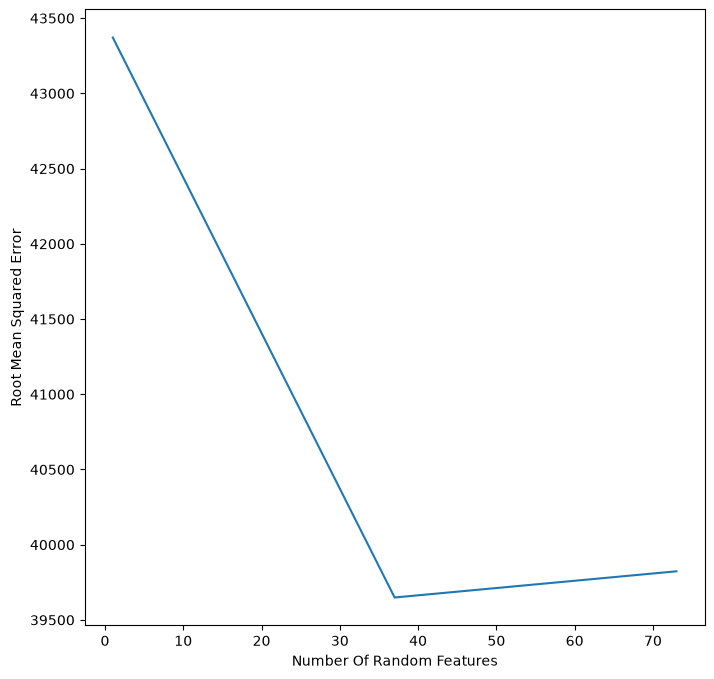

The best number of random features is 37 which gives a testing root mean squared error of 36555.253 and testing R squared score of 0.368.


,permutation_importance,sse_importance,direction
variables,,,
job_title_short_Data Analyst,14.17,18.67,-39286.491228
job_health_insurance,8.83,3.47,13290.040999
skills_excel,3.48,3.86,-13720.565345
job_via_LinkedIn,3.42,2.04,8311.270345
job_country_United States,3.29,1.08,4828.267450
skills_sql,3.22,2.80,-272.139573
skills_python,3.05,1.73,4743.790824
job_title_short_Data Engineer,2.96,1.11,-2767.023989
job_via_other,2.75,1.85,4250.009127


In [ ]:
random_feature_numbers = np.unique(np.linspace(1, X_training.shape[1], 25).astype(np.int32))
rmses = []
for random_feature_number in random_feature_numbers:
    rmses_one_fold = []
    for fold in mlm.kfold_cross_validation(5, len(y_training)):
        inner_model = mlm.Regression_Random_Forest(number_of_trees=25, number_of_random_features=random_feature_number)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0))
        predictions = inner_model.predict(X_training[fold])
        rmse = np.sqrt(np.mean((y_training[fold] - predictions)**2))
        rmses_one_fold.append(rmse)
    rmses.append([np.mean(rmses_one_fold), random_feature_number])
rmses = np.array(rmses)
row_number = np.argmin(rmses[:, 0])
best_random_feature_number = int(rmses[row_number, 1])

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(rmses[:, 1], rmses[:, 0])
ax.set_xlabel('Number Of Random Features')
ax.set_ylabel('Root Mean Squared Error')
plt.show()

full_model = mlm.Regression_Random_Forest(number_of_trees=1000, number_of_random_features=best_random_feature_number)
full_model.fit(X_training, y_training)
predictions = full_model.predict(X_testing)
rmse = np.sqrt(np.mean((y_testing - predictions)**2))
r2 = 1 - (np.sum((y_testing - predictions)**2)) / (np.sum((y_testing - np.mean(y_testing))**2))
print(f'The best number of random features is {best_random_feature_number} which gives a testing root mean squared error of {rmse:.3f} and testing R squared score of {r2:.3f}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'permutation_importance':np.round(full_model.permutation_importances(X_testing, y_testing) * 100, 2), 'sse_importance':np.round(full_model.feature_importances() * 100, 2), 'direction':full_model.direction_of_change()}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by='permutation_importance', ascending=False).set_index('variables', drop=True)
display(parameters_df)

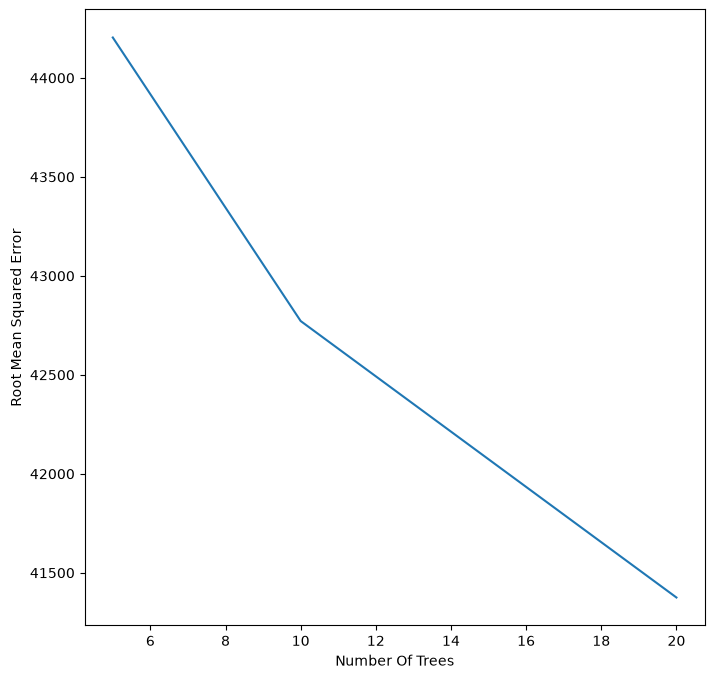

The best number of trees is 20 which gives a testing root mean squared error of 39945.722 and testing R squared score of 0.246.


,permutation_importance,sse_importance,direction
variables,,,
job_title_short_Data Analyst,32.91,53.36,-14267.803847
skills_excel,7.56,6.94,-4375.280459
job_title_short_Senior Data Scientist,7.30,4.42,4401.303378
skills_spark,7.19,2.49,2318.180774
skills_python,6.97,3.51,2087.326187
job_health_insurance,5.62,6.28,2846.989983
job_via_LinkedIn,4.88,3.58,2624.954774
job_via_BeBee,4.56,2.35,-2997.230492
job_country_other,4.06,1.86,-1670.957529


In [ ]:
number_of_trees = [5, 10, 20, 30, 40, 50, 75, 100, 150, 200, 250, 300, 350, 400, 500, 600, 700, 800, 900, 1000, 1250, 1500, 2000, 2500, 5000]
rmses = []
for tree_number in number_of_trees:
    rmses_one_fold = []
    for fold in mlm.kfold_cross_validation(5, len(y_training)):
        inner_model = mlm.Regression_Gradient_Boosting(number_of_trees=tree_number)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0))
        predictions = inner_model.predict(X_training[fold])
        rmse = np.sqrt(np.mean((y_training[fold] - predictions)**2))
        rmses_one_fold.append(rmse)
    rmses.append([np.mean(rmses_one_fold), tree_number])
rmses = np.array(rmses)
row_number = np.argmin(rmses[:, 0])
best_tree_number = int(rmses[row_number, 1])

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(rmses[:, 1], rmses[:, 0])
ax.set_xlabel('Number Of Trees')
ax.set_ylabel('Root Mean Squared Error')
plt.show()

full_model = mlm.Regression_Gradient_Boosting(number_of_trees=best_tree_number)
full_model.fit(X_training, y_training)
predictions = full_model.predict(X_testing, y_testing)
rmse = np.sqrt(np.mean((y_testing - predictions)**2))
r2 = 1 - (np.sum((y_testing - predictions)**2)) / (np.sum((y_testing - np.mean(y_testing))**2))
print(f'The best number of trees is {best_tree_number} which gives a testing root mean squared error of {rmse:.3f} and testing R squared score of {r2:.3f}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'permutation_importance':np.round(full_model.permutation_importances(X_testing, y_testing) * 100, 2), 'sse_importance':np.round(full_model.feature_importances() * 100, 2), 'direction':full_model.direction_of_change()}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by='permutation_importance', ascending=False).set_index('variables', drop=True)
display(parameters_df)